# Support Vector Machines and Kernels - Laboratorul 7
**Student:** Jalba Oleg  
**Curs:** Machine Learning / Învățare Automată

# Obiectivele cursului
- Aplicarea metodei vectorilor de suport (SVM) — un algoritm popular utilizat pentru sarcini de clasificare
- Recunoașterea similitudinii dintre SVM și regresia logistică
- Calcularea funcției de pierdere pentru SVM
- Aplicarea regularizării în SVM și studierea recomandărilor privind obținerea unei clasificări neliniare cu ajutorul SVM

## Introducere
În aceste exerciții vom folosi un set de date privind calitatea vinului. Acest set de date conține diverse proprietăți chimice ale vinului, precum aciditatea, conținutul de zahăr, pH-ul și conținutul de alcool. De asemenea, conține o măsură a calității (de la 3 la 9, unde scorul cel mai mare indică cea mai bună calitate) și culoarea (roșu sau alb). Numele fișierului: `Wine_Quality_Data.csv`.

In [1]:
from __future__ import print_function
import os
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except ImportError:
    pass

print("Bibliotecile au fost importate cu succes.")

Bibliotecile au fost importate cu succes.


## Întrebarea 1
* Importul datelor.
* Creați variabila țintă `y` sub forma unei coloane cu valori 1/0, unde 1 înseamnă vin roșu.
* Creați un grafic pereche pentru setul de date.
* Creați un grafic cu bare care să ilustreze corelația dintre fiecare coloană și `y`.
* Selectați cele două câmpuri cu cea mai mare corelație (folosind valorile corelației absolute) și creați `X`.
* Folosiți MinMaxScaler pentru a scala `X`. Rețineți că rezultatul va fi un np.array. Transformați-l din nou într-un DataFrame și redenumiți coloanele în consecință.

In [2]:
# 1. Importul setului de date
filepath = os.path.join(*data_path, 'Wine_Quality_Data.csv')
data = pd.read_csv(filepath)

print(f"Setul de date conține {data.shape[0]} instanțe și {data.shape[1]} coloane.")
print("\nPrimele 5 linii din setul de date:")
display(data.head())

# 2. Crearea variabilei tinta y (1 = vin rosu, 0 = vin alb)
y = (data['color'] == 'red').astype(int)

print("\nDistribuția claselor în y:")
print(f"Număr vinuri albe (0): {(y == 0).sum()} ({(y == 0).mean()*100:.2f}%)")
print(f"Număr vinuri roșii (1): {(y == 1).sum()} ({(y == 1).mean()*100:.2f}%)")

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Setul de date conține 6497 instanțe și 13 coloane.

Primele 5 linii din setul de date:

Distribuția claselor în y:
Număr vinuri albe (0): 4898 (75.39%)
Număr vinuri roșii (1): 1599 (24.61%)


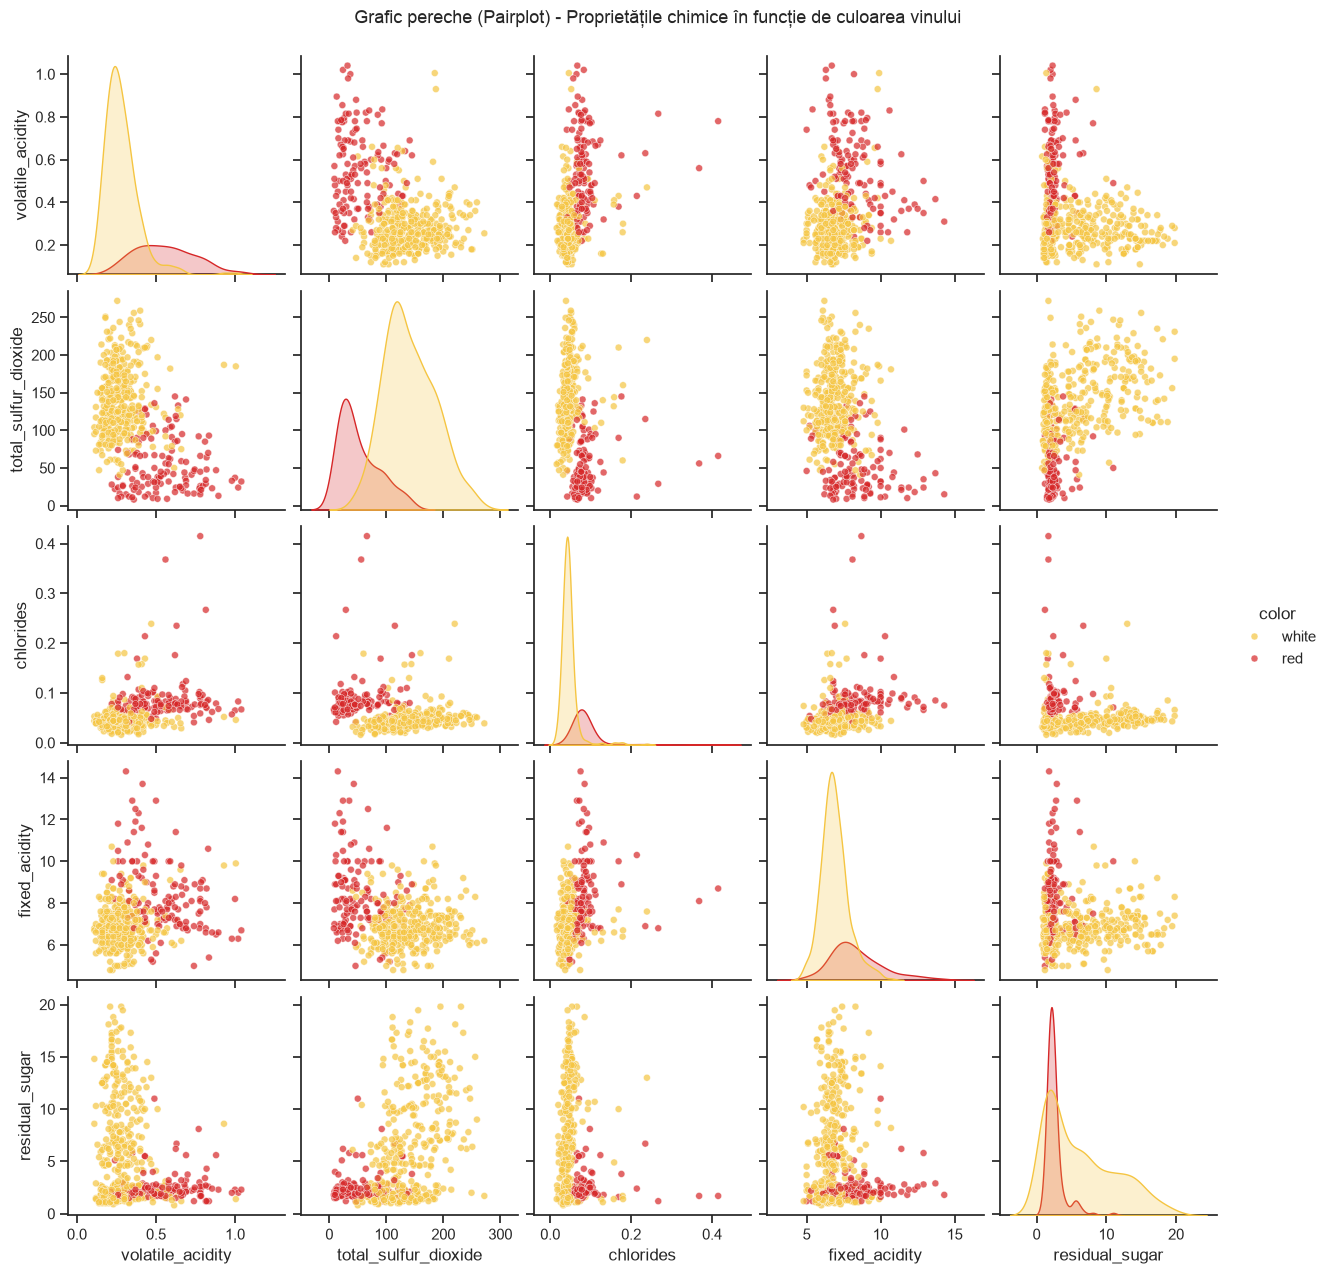

In [3]:
# 3. Grafic pereche (Pairplot)
# Pentru claritate vizuala si eficienta de randare, selectam un esantion reprezentativ de 500 mostre
sample_df = data.sample(n=500, random_state=42)

# Selectam caracteristicile chimice principale pentru vizualizare
features_subset = ['volatile_acidity', 'total_sulfur_dioxide', 'chlorides', 'fixed_acidity', 'residual_sugar', 'color']

sns.set_theme(style="ticks")
pairplot_fig = sns.pairplot(
    sample_df[features_subset],
    hue='color',
    palette={'red': '#d62728', 'white': '#f5c542'},
    diag_kind='kde',
    plot_kws={'alpha': 0.7, 's': 25}
)
pairplot_fig.fig.suptitle("Grafic pereche (Pairplot) - Proprietățile chimice în funcție de culoarea vinului", y=1.02, fontsize=13)
plt.show()

,total_sulfur_dioxide,volatile_acidity
0,0.064516,0.413333
1,0.140553,0.533333
2,0.110599,0.453333
3,0.124424,0.133333
4,0.064516,0.413333


Cele două coloane cu cea mai mare corelație absolută: ['total_sulfur_dioxide', 'volatile_acidity']
1. total_sulfur_dioxide: corelație = -0.7004 (abs = 0.7004)
2. volatile_acidity: corelație = 0.6530 (abs = 0.6530)

Primele 5 linii din X scalat cu MinMaxScaler [0, 1]:


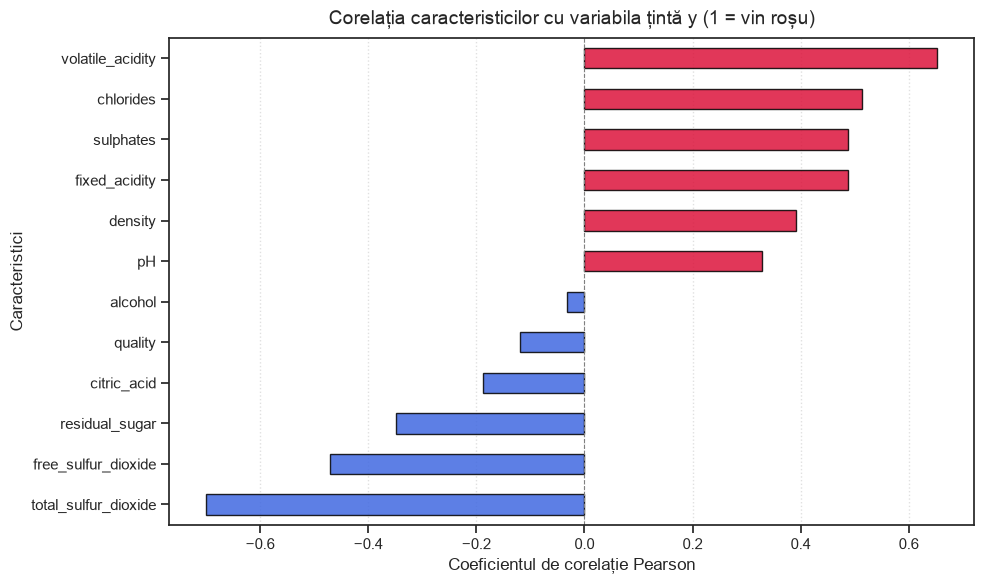

In [4]:
# 4. Corelatia fiecarei coloane numerice cu variabila tinta y
numeric_fields = [c for c in data.columns if c != 'color']
correlations = data[numeric_fields].apply(lambda col: col.corr(y))
sorted_corrs = correlations.sort_values()

plt.figure(figsize=(10, 6))
colors_bar = ['crimson' if val > 0 else 'royalblue' for val in sorted_corrs.values]
sorted_corrs.plot(kind='barh', color=colors_bar, edgecolor='black', alpha=0.85)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.title("Corelația caracteristicilor cu variabila țintă y (1 = vin roșu)", fontsize=14, pad=10)
plt.xlabel("Coeficientul de corelație Pearson", fontsize=12)
plt.ylabel("Caracteristici", fontsize=12)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# 5. Selectarea celor doua campuri cu cea mai mare corelatie absoluta
abs_corrs = correlations.abs().sort_values(ascending=False)
top_2_fields = abs_corrs.index[:2].tolist()
print(f"Cele două coloane cu cea mai mare corelație absolută: {top_2_fields}")
print(f"1. {top_2_fields[0]}: corelație = {correlations[top_2_fields[0]]:.4f} (abs = {abs_corrs[top_2_fields[0]]:.4f})")
print(f"2. {top_2_fields[1]}: corelație = {correlations[top_2_fields[1]]:.4f} (abs = {abs_corrs[top_2_fields[1]]:.4f})")

X = data[top_2_fields]

# 6. Scalarea cu MinMaxScaler si reconstituirea DataFrame-ului
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(X_scaled, columns=top_2_fields)

print("\nPrimele 5 linii din X scalat cu MinMaxScaler [0, 1]:")
display(X.head())

## Întrebarea 2

Scopul acestei întrebări este de a analiza pragul de decizie al clasificatorului LinearSVC pentru setul de date dat.

* Configurați clasificatorul LinearSVC pe `X` și `y`.
* Selectați 300 de eșantioane din `X`. Obțineți valorile corespunzătoare ale `y`. Salvați-le în variabilele `X_color` și `y_color`. Acest lucru se datorează faptului că setul de date original este prea mare și generează un grafic supraîncărcat.
* Modificați `y_color` astfel încât valoarea „roșu” să înlocuiască 1, iar „galben” să înlocuiască 0.
* Graficul de dispersie pentru coloanele X_color. Utilizați argumentul cu cuvântul-cheie „color=y_color” pentru a afișa codul culorii.
* Utilizați fragmentul de cod din cerință pentru a desena suprafața soluției în culori.

Acuratețea modelului LinearSVC pe datele scalate: 0.9546 (95.46%)


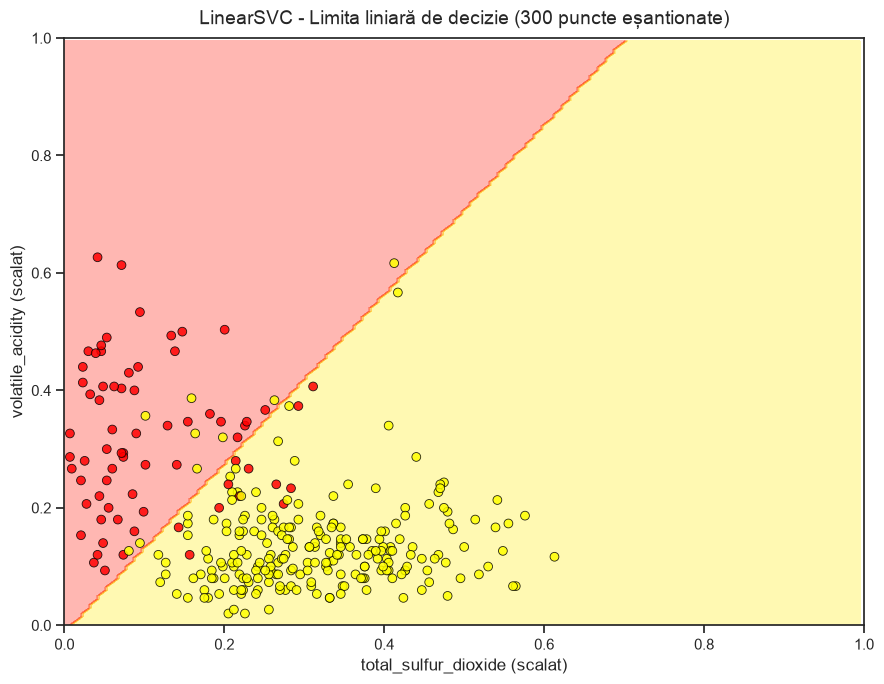

In [5]:
# 1. Antrenarea clasificatorului LinearSVC
linear_svc = LinearSVC(random_state=42, max_iter=5000)
linear_svc.fit(X, y)

# 2. Selectarea unui esantion aleatoriu de 300 de observatii
sample_idx = np.random.RandomState(42).choice(X.index, size=300, replace=False)
X_color = X.iloc[sample_idx]
y_color = y.iloc[sample_idx]

# 3. Transformarea etichetelor: 1 -> 'red', 0 -> 'yellow'
y_color = y_color.map({1: 'red', 0: 'yellow'})

# 4 & 5. Graficul de dispersie si suprafata de decizie cu ax.contourf
fig, ax = plt.subplots(figsize=(9, 7))

# Generarea grilei de coordonate
x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
xx, yy = np.meshgrid(x_axis, y_axis)
xx_ravel = xx.ravel()
yy_ravel = yy.ravel()
X_grid = pd.DataFrame([xx_ravel, yy_ravel]).T
X_grid.columns = X.columns

y_grid_predictions = linear_svc.predict(X_grid)
y_grid_predictions = y_grid_predictions.reshape(xx.shape)

# Afisarea suprafetei de decizie
ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)

# Afisarea punctelor esantionate
ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, edgecolors='black', linewidth=0.6, s=40, alpha=0.85)

ax.set_xlabel(f"{X.columns[0]} (scalat)", fontsize=12)
ax.set_ylabel(f"{X.columns[1]} (scalat)", fontsize=12)
ax.set_title("LinearSVC - Limita liniară de decizie (300 puncte eșantionate)", fontsize=14, pad=10)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

# Evaluarea acuratetei LinearSVC
acc_linear = accuracy_score(y, linear_svc.predict(X))
print(f"Acuratețea modelului LinearSVC pe datele scalate: {acc_linear:.4f} ({acc_linear*100:.2f}%)")

## Întrebarea 3

Să extindem acum nucleul Gauss al SVC și să vedem cum se modifică limita de decizie.

* Combinați fragmentele de cod din întrebarea 2 într-o singură funcție, care utilizează estimatorul `X` și `y` și va genera graficul final cu limita de decizie. Pași:
    <ol>
     <li> modelul potrivit
     <li> obțineți un eșantion de 300 de înregistrări din X și valorile corespunzătoare ale lui y
     <li> creați o rețea, faceți predicții, generați un grafic folosind ax.contourf
     <li> adăugați-l la graficul dispersat
    </ol>
* După copierea și inserarea codului, asigurați-vă că funcția finală utilizează `estimatorul` dvs. de intrare, nu modelul LinearSVC creat de dvs.
* Pentru următoarele valori ale lui `gamma`, creați un SVC cu kernel gaussian și desenați curba de decizie:
  `gammas = [.5, 1, 2, 10]`
* Menținând `gamma` constantă, pentru diferite valori ale lui `C`, desenați curba de decizie:
  `Cs = [.1, 1, 10]`

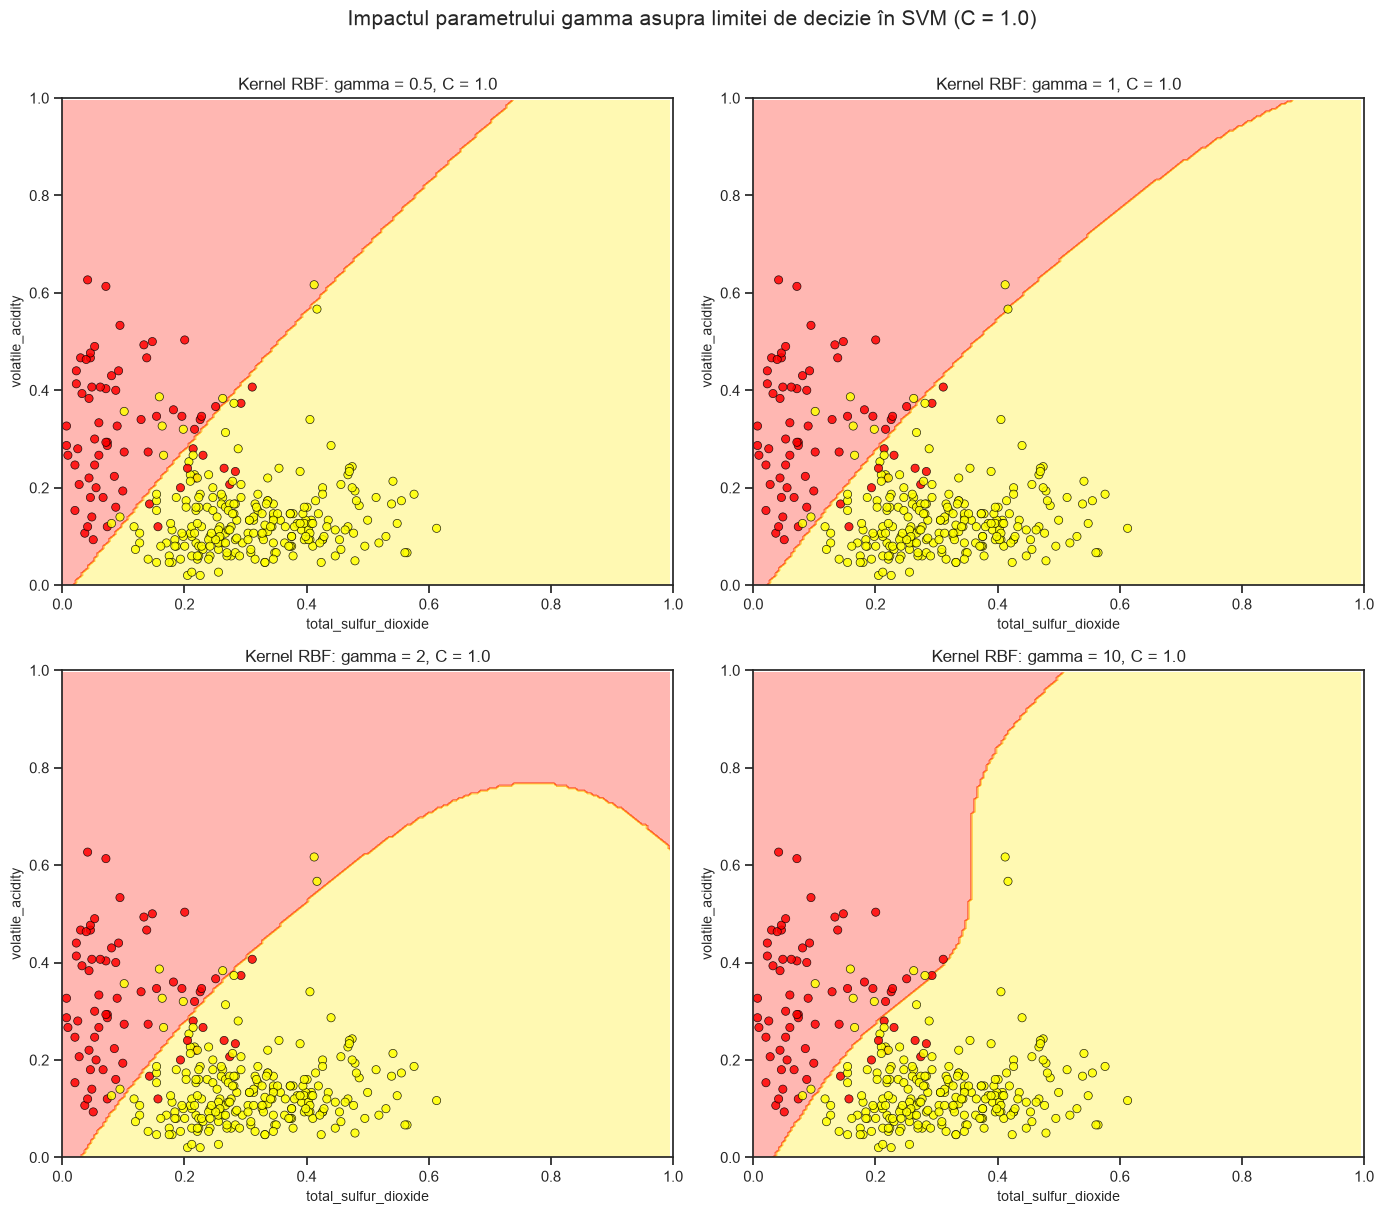

In [6]:
def plot_decision_boundary(estimator, X, y, title=None, ax=None):
    # Functie modulara care antreneaza un estimator si deseneaza limita de decizie
    # impreuna cu un esantion de 300 de puncte.
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    
    # 1. Antrenarea estimatorului
    estimator.fit(X, y)
    
    # 2. Esantion de 300 de inregistrari din X si y corespunzator
    sample_indices = np.random.RandomState(42).choice(X.index, size=300, replace=False)
    X_color = X.iloc[sample_indices]
    y_color = y.iloc[sample_indices].map({1: 'red', 0: 'yellow'})
    
    # 3. Crearea grilei si realizarea predictiilor
    x_axis, y_axis = np.arange(0, 1, .005), np.arange(0, 1, .005)
    xx, yy = np.meshgrid(x_axis, y_axis)
    X_grid = pd.DataFrame([xx.ravel(), yy.ravel()]).T
    X_grid.columns = X.columns
    
    y_grid_predictions = estimator.predict(X_grid)
    y_grid_predictions = y_grid_predictions.reshape(xx.shape)
    
    # Desenarea suprafetei de decizie
    ax.contourf(xx, yy, y_grid_predictions, cmap=plt.cm.autumn_r, alpha=.3)
    
    # 4. Adaugarea punctelor esantionate
    ax.scatter(X_color.iloc[:, 0], X_color.iloc[:, 1], color=y_color, edgecolors='black', linewidth=0.5, s=35, alpha=0.85)
    
    ax.set_xlabel(f"{X.columns[0]}", fontsize=10)
    ax.set_ylabel(f"{X.columns[1]}", fontsize=10)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    if title:
        ax.set_title(title, fontsize=12)

# Variatia parametrului gamma pentru nucleul Gaussian (RBF) cu C=1.0 constant
gammas = [0.5, 1, 2, 10]

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for i, gamma in enumerate(gammas):
    svc_gamma = SVC(kernel='rbf', gamma=gamma, C=1.0, random_state=42)
    plot_decision_boundary(svc_gamma, X, y, title=f"Kernel RBF: gamma = {gamma}, C = 1.0", ax=axes[i])

plt.suptitle("Impactul parametrului gamma asupra limitei de decizie în SVM (C = 1.0)", fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

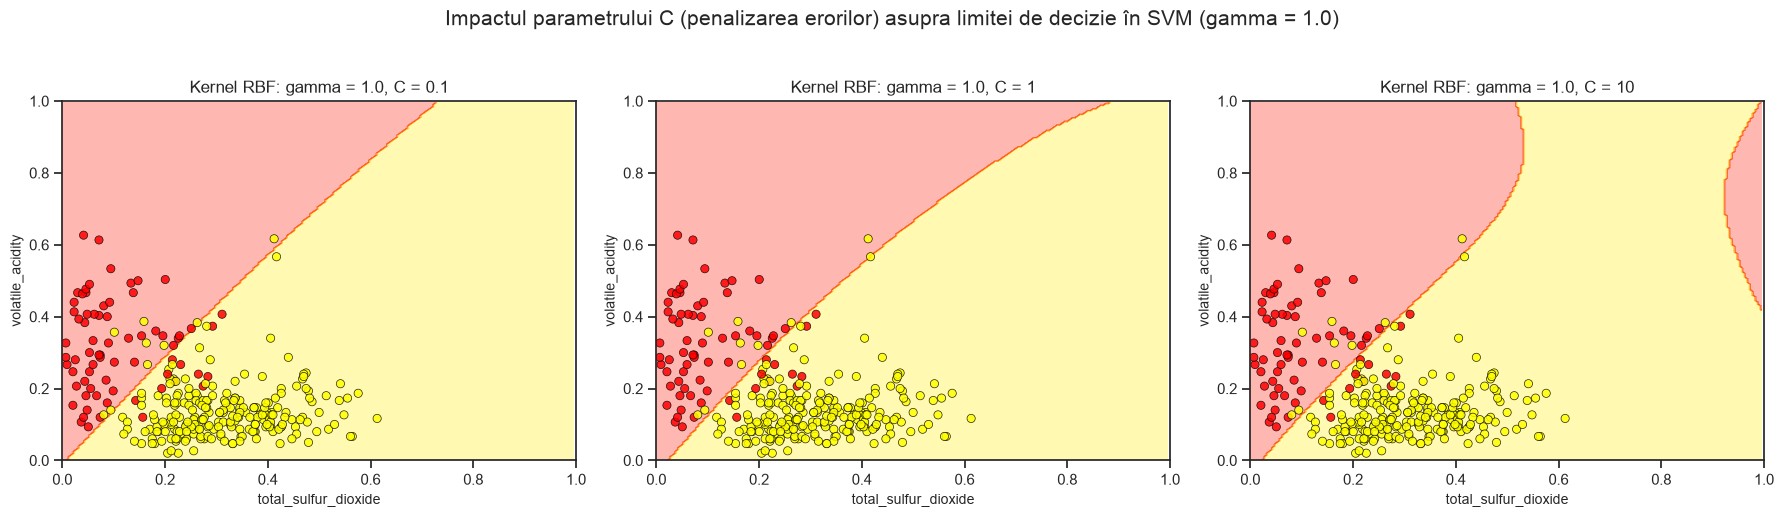

In [7]:
# Variatia parametrului C cu gamma constant (gamma = 1.0)
Cs = [0.1, 1, 10]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, C_val in enumerate(Cs):
    svc_c = SVC(kernel='rbf', gamma=1.0, C=C_val, random_state=42)
    plot_decision_boundary(svc_c, X, y, title=f"Kernel RBF: gamma = 1.0, C = {C_val}", ax=axes[i])

plt.suptitle("Impactul parametrului C (penalizarea erorilor) asupra limitei de decizie în SVM (gamma = 1.0)", fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

### Observații privind influența parametrilor `gamma` și `C`:
- **Parametrul `gamma`**: Controlează raza de influență a fiecărui vector de suport. O valoare mică a lui gamma (ex. 0.5) generează o frontieră de decizie mai lină (similară cu un model liniar), în timp ce o valoare mare (ex. 10) determină frontiere foarte strânse în jurul punctelor de date, crescând riscul de *overfitting*.
- **Parametrul `C`**: Reglează compromisul între marja largă și clasificarea corectă a fiecărui punct. O valoare mică a lui $C$ ($0.1$) permite o marjă mai largă și tolerează erori de clasificare (crește bias-ul, scade varianța). O valoare mare a lui $C$ ($10$) penalizează puternic erorile, forțând o margine mai strictă.

## Întrebarea 4

În această întrebare vom compara timpul de execuție între SVC și Nystroem cu nucleul rbf.

* Reîncărcați datele privind calitatea vinului dacă ați adus modificări la original.
* Creați variabila `y` din coloana `data.color` și `X` din celelalte coloane.
* Măsurați timpul necesar configurării SVC cu nucleul RBF.
* Măsurați timpul necesar următoarei operațiuni: ordonați datele folosind Nystroem, apoi integrați clasificatorul SGD.
* Faceți 5 copii ale lui X și corelați-le (concatenare).
* Faceți 5 copii ale lui y și corelați-le.
* Comparați timpul necesar pentru antrenarea ambelor metode pe setul de date mărit.

In [8]:
# 1. Reincarcarea datelor
data_fresh = pd.read_csv(filepath)

# 2. Crearea y si X pe toate coloanele
y_fresh = (data_fresh['color'] == 'red').astype(int)
X_fresh = data_fresh.drop(columns=['color'])

# Scalam toate variabilele pentru convergenta rapida si corecta a algoritmilor
scaler_full = MinMaxScaler()
X_fresh_scaled = pd.DataFrame(scaler_full.fit_transform(X_fresh), columns=X_fresh.columns)

print(f"Setul complet conține: {X_fresh_scaled.shape[0]} rânduri și {X_fresh_scaled.shape[1]} caracteristici.")

# Functie pentru masurarea timpului de antrenare
def measure_training_time(X_train, y_train):
    # a) SVC cu nucleu RBF
    start_svc = time.time()
    svc_model = SVC(kernel='rbf', random_state=42)
    svc_model.fit(X_train, y_train)
    time_svc = time.time() - start_svc
    acc_svc = accuracy_score(y_train, svc_model.predict(X_train))
    
    # b) Nystroem (aproximare RBF) + SGDClassifier
    start_nys = time.time()
    nystroem = Nystroem(kernel='rbf', random_state=42, n_components=100)
    X_train_transformed = nystroem.fit_transform(X_train)
    sgd_model = SGDClassifier(loss='hinge', random_state=42, max_iter=1000)
    sgd_model.fit(X_train_transformed, y_train)
    time_nys = time.time() - start_nys
    acc_nys = accuracy_score(y_train, sgd_model.predict(X_train_transformed))
    
    return time_svc, acc_svc, time_nys, acc_nys

t_svc_1x, a_svc_1x, t_nys_1x, a_nys_1x = measure_training_time(X_fresh_scaled, y_fresh)

print("=== Rezultate pe setul de date original (6,497 mostre) ===")
print(f"SVC (Exact RBF Kernel):      Timp = {t_svc_1x:.4f} sec | Acuratețe = {a_svc_1x*100:.2f}%")
print(f"Nystroem + SGDClassifier:    Timp = {t_nys_1x:.4f} sec | Acuratețe = {a_nys_1x*100:.2f}%")
print(f"Accelerare Nystroem vs SVC:  {t_svc_1x / t_nys_1x:.2f}x mai rapid")

Setul complet conține: 6497 rânduri și 12 caracteristici.
=== Rezultate pe setul de date original (6,497 mostre) ===
SVC (Exact RBF Kernel):      Timp = 0.0394 sec | Acuratețe = 99.58%
Nystroem + SGDClassifier:    Timp = 0.0259 sec | Acuratețe = 99.01%
Accelerare Nystroem vs SVC:  1.52x mai rapid


Dimensiunea noului set mărit de 5 ori: 32485 rânduri, 12 coloane.

=== Rezultate pe setul mărit de 5x (32,485 mostre) ===
SVC (Exact RBF Kernel):      Timp = 0.6438 sec | Acuratețe = 99.72%
Nystroem + SGDClassifier:    Timp = 0.1017 sec | Acuratețe = 99.03%
Accelerare Nystroem vs SVC:  6.33x mai rapid


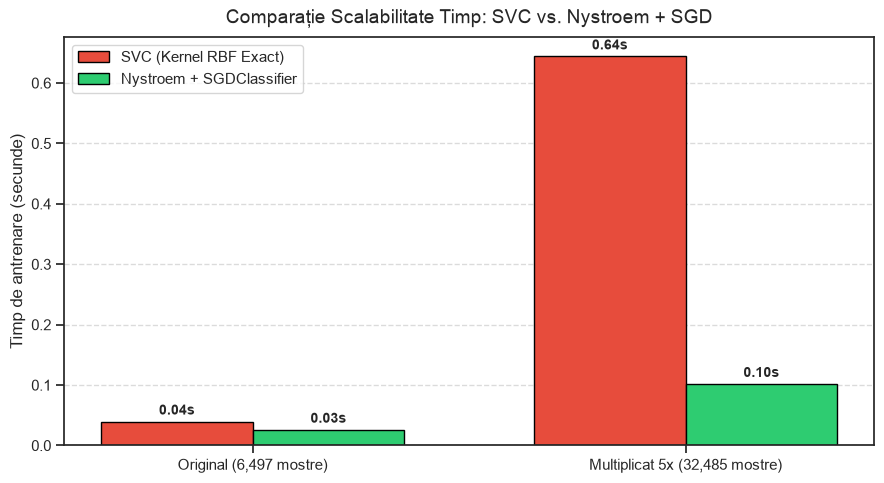

In [9]:
# 3 & 4. Multiplicarea de 5 ori a setului de date (concatenare)
X_5x = pd.concat([X_fresh_scaled] * 5, ignore_index=True)
y_5x = pd.concat([y_fresh] * 5, ignore_index=True)

print(f"Dimensiunea noului set mărit de 5 ori: {X_5x.shape[0]} rânduri, {X_5x.shape[1]} coloane.")

# Masurarea timpului pe setul de date de 5x
t_svc_5x, a_svc_5x, t_nys_5x, a_nys_5x = measure_training_time(X_5x, y_5x)

print("\n=== Rezultate pe setul mărit de 5x (32,485 mostre) ===")
print(f"SVC (Exact RBF Kernel):      Timp = {t_svc_5x:.4f} sec | Acuratețe = {a_svc_5x*100:.2f}%")
print(f"Nystroem + SGDClassifier:    Timp = {t_nys_5x:.4f} sec | Acuratețe = {a_nys_5x*100:.2f}%")
print(f"Accelerare Nystroem vs SVC:  {t_svc_5x / t_nys_5x:.2f}x mai rapid")

# Comparatie vizuala a timpilor de executie
fig, ax = plt.subplots(figsize=(9, 5))
datasets = ['Original (6,497 mostre)', 'Multiplicat 5x (32,485 mostre)']
svc_times = [t_svc_1x, t_svc_5x]
nys_times = [t_nys_1x, t_nys_5x]

x_indices = np.arange(len(datasets))
bar_width = 0.35

rects1 = ax.bar(x_indices - bar_width/2, svc_times, bar_width, label='SVC (Kernel RBF Exact)', color='#e74c3c', edgecolor='black')
rects2 = ax.bar(x_indices + bar_width/2, nys_times, bar_width, label='Nystroem + SGDClassifier', color='#2ecc71', edgecolor='black')

ax.set_ylabel('Timp de antrenare (secunde)', fontsize=12)
ax.set_title('Comparație Scalabilitate Timp: SVC vs. Nystroem + SGD', fontsize=14, pad=10)
ax.set_xticks(x_indices)
ax.set_xticklabels(datasets, fontsize=11)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Adaugam etichete cu valorile numerice deasupra barelor
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}s',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

## Concluzii Laboratorul 7:
1. **Separabilitate și Trăsături Relevante**: Analiza de corelație a evidențiat că `total_sulfur_dioxide` și `volatile_acidity` au cea mai puternică corelație cu tipul de vin, permițând obținerea unei acurateți ridicate chiar și într-un spațiu bidimensional redus.
2. **LinearSVC vs. RBF Kernel**: LinearSVC determină un hiperplan liniar de separare rigid. Kernel-ul Gaussian (RBF) conferă flexibilitate, adaptându-se la contururi neliniare.
3. **Hiperparametrii gamma și C**:
   - `gamma` controlează curbura și granularitatea frontierei de decizie.
   - `C` controlează severitatea penalizării erorilor de margine.
4. **Scalabilitate computațională (Nystroem + SGD)**:
   - Antrenarea standard SVM cu kernel exact are complexitate temporală între $\mathcal{O}(N^2)$ și $\mathcal{O}(N^3)$, devenind prohibitivă la seturi mari de date.
   - Tehnica de aproximare prin caracteristici **Nystroem** combinată cu **SGDClassifier** (Stochastic Gradient Descent) scalează liniar $\mathcal{O}(N)$, fiind considerabil mai rapidă la volume mari de date fără a sacrifica semnificativ acuratețea.